## 신항 6부두 vs 7부두: 개장 후 분기별 처리능력 대비 물동량

- 물동량: 체인포털 > 빅데이터 > 부산항 물동량 현황 > 컨테이너 별 > 시설별 화물처리 실적 (분기 단독 값, 천TEU, 항만 전체 필터)
- 처리능력: 하역능력 6부두 195만 TEU/년(부산지방해양수산청 신항 부두현황 1,950천TEU, 해수부 6부두 개장 보도자료 2022-09-02), 7부두 195만 TEU/년(서컨 2-5단계, 해수부·BPA 준공 발표 보도 2023-10-26, 해양한국 2024-09-30)
- 분기 처리능력 = 연간 능력 ÷ 4 × 운영 선석·일수 비율 (선석 운영 시작일 = 선석별 첫 입항일)
- 경과분기 1 = 공식 개장 분기 (6부두 2022Q2, 7부두 2024Q2). 7부두 2024Q1은 시운전이라 제외합니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

# 한글 폰트 설정 (Windows: 맑은 고딕, macOS: AppleGothic, 기타: 나눔고딕)
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic']:
    if f in {x.name for x in fm.fontManager.ttflist}:
        plt.rcParams['font.family'] = f
        break
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

## 1. 데이터 입력
체인포털에서 조회한 분기별 물동량(천TEU)입니다. 수집해 둔 CSV를 쓰려면 아래 주석을 해제하세요.

In [2]:
quarters = pd.period_range('2022Q1', '2026Q3', freq='Q')
pier6 = [None, 22, 91, 89, 126, 203, 224, 235, 275, 325, 342, 296, 397, 458, 421, 439, 434, 456, 465]
pier7 = [None] * 8 + [19, 137, 215, 192, 272, 289, 269, 264, 294, 354, 463]
raw = pd.DataFrame({'분기': quarters, '6부두': pier6, '7부두': pier7})

# csv = pd.read_csv(r'D:\Users\KIM TAE-HONG\Desktop\do work claude\chainportal_pier67_quarterly.csv', encoding='utf-8-sig')
# raw = pd.DataFrame({'분기': pd.PeriodIndex.from_fields(year=csv['year'], quarter=csv['quarter'], freq='Q'),
#                     '6부두': csv['pier6_kTEU'], '7부두': csv['pier7_kTEU']})
raw

,분기,6부두,7부두
0,2022Q1,NaN,NaN
1,2022Q2,22.0,NaN
2,2022Q3,91.0,NaN
3,2022Q4,89.0,NaN
4,2023Q1,126.0,NaN
5,2023Q2,203.0,NaN
6,2023Q3,224.0,NaN
7,2023Q4,235.0,NaN
8,2024Q1,275.0,19.0
9,2024Q2,325.0,137.0


## 2. 처리능력 가정

In [3]:
CAPACITY = {'6부두': 1950, '7부두': 1950}  # 하역능력, 천TEU/년
BERTH_START = {  # 선석별 운영 시작일 (첫 입항일)
    '6부두': ['2022-04-02', '2022-06-10', '2022-10-26'],
    '7부두': ['2024-03-11', '2024-03-13', '2024-03-12'],
}
OPENING_Q = {'6부두': pd.Period('2022Q2'), '7부두': pd.Period('2024Q2')}  # 공식 개장 분기
N_BERTH = 3

## 3. 분기별 가동률 계산

In [4]:
rows = []
for pier in ['6부두', '7부두']:
    for q, v in zip(raw['분기'], raw[pier]):
        if pd.isna(v):
            continue
        start, end = q.start_time, q.end_time.normalize() + pd.Timedelta(days=1)
        days = (end - start).days
        berth_days = sum(max(0, (end - max(start, pd.Timestamp(b))).days) for b in BERTH_START[pier])
        frac = berth_days / (N_BERTH * days)                      # 운영 선석·일수 비율
        q_cap = CAPACITY[pier] / 4 * frac * days / (365.25 / 4)   # 분기 처리능력(천TEU)
        rows.append({
            '부두': pier, '분기': str(q), '경과분기': (q - OPENING_Q[pier]).n + 1,
            '물동량_천TEU': v, '운영선석비율': round(frac, 3),
            '분기처리능력_천TEU': round(q_cap, 1),
            '가동률_pct': round(v / q_cap * 100, 1),
            '선석당_천TEU': round(v / (N_BERTH * frac), 1),
        })
df = pd.DataFrame(rows)
df

,부두,분기,경과분기,물동량_천TEU,운영선석비율,분기처리능력_천TEU,가동률_pct,선석당_천TEU
0,6부두,2022Q2,1,22.0,0.407,197.5,11.1,18.0
1,6부두,2022Q3,2,91.0,0.667,327.4,27.8,45.5
2,6부두,2022Q4,3,89.0,0.909,446.7,19.9,32.6
3,6부두,2023Q1,4,126.0,1.000,480.5,26.2,42.0
4,6부두,2023Q2,5,203.0,1.000,485.8,41.8,67.7
5,6부두,2023Q3,6,224.0,1.000,491.2,45.6,74.7
6,6부두,2023Q4,7,235.0,1.000,491.2,47.8,78.3
7,6부두,2024Q1,8,275.0,1.000,485.8,56.6,91.7
8,6부두,2024Q2,9,325.0,1.000,485.8,66.9,108.3
9,6부두,2024Q3,10,342.0,1.000,491.2,69.6,114.0


## 4. 경과분기 기준 비교표

In [5]:
plot_df = df[df['경과분기'] >= 1]
table = plot_df.pivot(index='경과분기', columns='부두', values='가동률_pct')
table.columns = [f'{c} 가동률(%)' for c in table.columns]
table

,6부두 가동률(%),7부두 가동률(%)
경과분기,,
1,11.1,28.2
2,27.8,43.8
3,19.9,39.1
4,26.2,56.6
5,41.8,59.5
6,45.6,54.8
7,47.8,53.7
8,56.6,61.2
9,66.9,72.9


## 5. 비교 선그래프

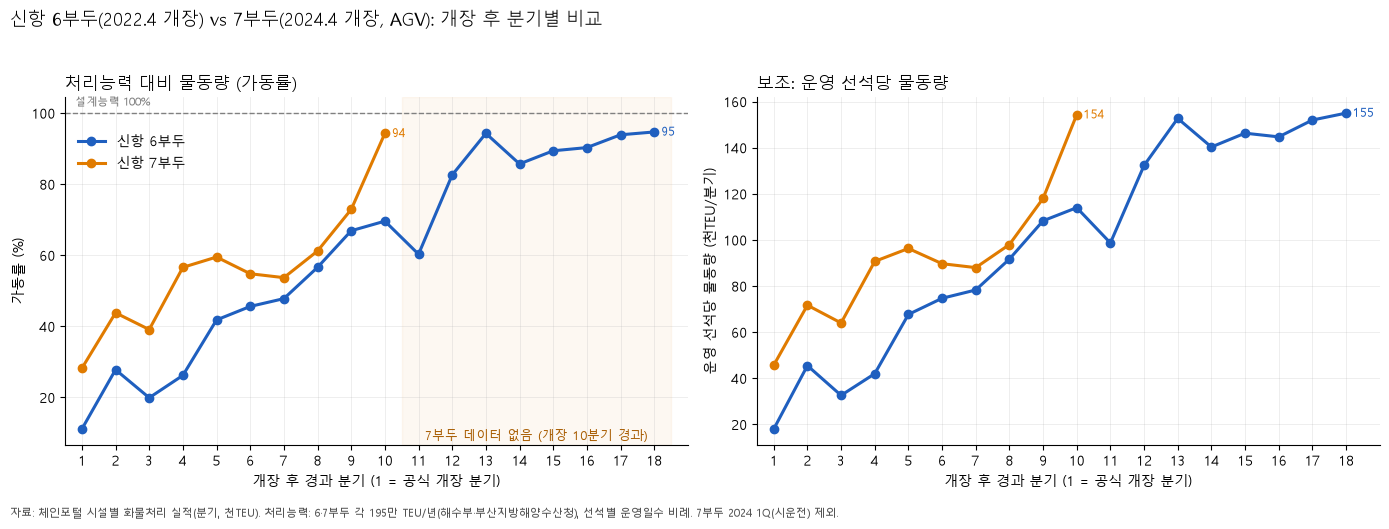

In [6]:
COLORS = {'6부두': '#1f5fbf', '7부두': '#e07b00'}
max_q = int(plot_df['경과분기'].max())
last7 = int(plot_df.loc[plot_df['부두'] == '7부두', '경과분기'].max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
panels = [('가동률_pct', '가동률 (%)', '처리능력 대비 물동량 (가동률)'),
          ('선석당_천TEU', '운영 선석당 물동량 (천TEU/분기)', '보조: 운영 선석당 물동량')]
for ax, (col, ylabel, title) in zip(axes, panels):
    for pier, c in COLORS.items():
        d = plot_df[plot_df['부두'] == pier]
        ax.plot(d['경과분기'], d[col], marker='o', lw=2.2, color=c, label=f'신항 {pier}')
        last = d.iloc[-1]
        ax.annotate(f'{last[col]:.0f}', (last['경과분기'], last[col]), xytext=(5, 0),
                    textcoords='offset points', color=c, va='center', fontsize=9)
    ax.set(xlabel='개장 후 경과 분기 (1 = 공식 개장 분기)', ylabel=ylabel)
    ax.set_title(title, loc='left', fontsize=12)
    ax.set_xticks(range(1, max_q + 1)); ax.set_xlim(0.5, max_q + 1)
    ax.grid(alpha=.3); ax.spines[['top', 'right']].set_visible(False)

axes[0].axhline(100, color='gray', ls='--', lw=1)
axes[0].text(0.8, 101.5, '설계능력 100%', fontsize=8, color='gray', va='bottom')
axes[0].axvspan(last7 + 0.5, max_q + 0.5, color='#e07b00', alpha=.05)
axes[0].text((last7 + max_q) / 2 + 0.5, 8, f'7부두 데이터 없음 (개장 {last7}분기 경과)',
             ha='center', fontsize=9, color='#a85c00')
axes[0].legend(frameon=False, loc='upper left', bbox_to_anchor=(0, 0.93))
fig.suptitle('신항 6부두(2022.4 개장) vs 7부두(2024.4 개장, AGV): 개장 후 분기별 비교', x=0.01, ha='left', fontsize=13)
fig.text(0.01, 0.005, '자료: 체인포털 시설별 화물처리 실적(분기, 천TEU). 처리능력: 6·7부두 각 195만 TEU/년(해수부·부산지방해양수산청), '
         '선석별 운영일수 비례. 7부두 2024 1Q(시운전) 제외.', fontsize=8, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 6. 결론

같은 개장 경과 시점에서 비교하면 AGV를 도입한 7부두는 매 분기 6부두보다 처리능력 대비 물동량(가동률)이 높습니다(1분기 28.2% vs 11.1%, 4분기 56.6% vs 26.2%, 8분기 61.2% vs 56.6%, 10분기 94.3% vs 69.6%). 운영 선석당 물동량 기준으로 봐도 같은 결과가 나오므로, '7부두 증가세가 지속적으로 낮아 운영 안정성이나 선사 유치를 조사해야 한다'는 시나리오에는 해당하지 않습니다. 기울기는 구간마다 다릅니다. 개장 후 1년 동안은 7부두가 더 가파르게 올랐습니다(+28%p, 6부두 +15%p). 2025년(4~8분기)에는 54-61%에서 정체해 같은 구간 6부두(+30%p)와 격차가 좁혀졌는데, 이 구간은 신규 터미널 안정화 기간 가설에 부합합니다. 이후 2026년 2·3분기에 94%까지 급등했습니다. 따라서 이 결과는 AGV 도입을 긍정적으로 검토할 수 있는 보조 근거입니다. 다만 7부두가 부산항 전체 물동량이 약 12% 더 큰 시기에 개장했고, 2026년 3분기에는 부산항 전체가 역대 최고치를 기록했다는 점을 함께 고려해야 합니다. 두 부두의 공식 하역능력은 195만 TEU/년으로 같으므로, 가동률 차이는 물동량 차이를 그대로 반영합니다. 결정적 근거로 쓰려면 선사·항로 배치 변화와 생산성 지표(선석 생산성, 재항시간)를 추가로 확인할 필요가 있습니다.